# Lezione 7 — Creatività, ironia e bias: che cosa non comprendono i modelli?
**Machine Learning for the Humanities · 18 novembre**

[![Apri in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/yuri-bizzoni/yuribizzoni/blob/main/ml-humanities/lessons/07_semantica_distribuzionale.ipynb)

**Laboratorio:** rappresentare testi come vettori, confrontare similarità, discutere gli *embeddings*.
**Metodo:** semantica distribuzionale.

> *"You shall know a word by the company it keeps."* — J. R. Firth, 1957

L'idea della **semantica distribuzionale** è semplice e potente: parole che compaiono in **contesti simili** hanno
**significati simili**. Se *gioia* e *letizia* stanno spesso vicino a *cuore, dolce, sentire*, allora un computer può
scoprire che si somigliano, anche senza sapere che cosa vogliono dire. È l'idea che sta alla base degli *embeddings*
e, molto più in grande, dei modelli linguistici come ChatGPT.

Oggi costruiamo da zero dei **vettori di parole** sul corpus del corso e li usiamo per esplorare la gradazione della felicità
(*felicità, gioia, allegria, contentezza, letizia*). Poi cerchiamo i loro limiti: **ironia**, **creatività**, **bias**.

### Obiettivi di apprendimento
1. spiegare l'ipotesi distribuzionale e che cos'è un *embedding*;
2. costruire vettori di parole da una matrice di co-occorrenze (PPMI + SVD);
3. trovare i "vicini" di una parola e misurare similarità;
4. rappresentare un testo come media di vettori;
5. discutere che cosa gli embeddings **non** vedono (ironia, parole nuove) e che cosa **ereditano** (bias).

In [1]:
# ⚙️ CELLA DI PREPARAZIONE — eseguitela per prima (Shift+Invio) e non preoccupatevi del codice.
# Cerca la cartella "data" del corso; se non la trova (per esempio su Google Colab),
# scarica il materiale del corso da GitHub. Funziona anche senza internet, se avete la cartella.
from pathlib import Path
import subprocess

def trova_dati():
    for p in [Path("../data"), Path("data"), Path("ml-humanities/data"), Path("yuribizzoni/ml-humanities/data")]:
        if (p / "lessico_felicita.csv").exists():
            return p
    subprocess.run(["git", "clone", "--depth", "1", "https://github.com/yuri-bizzoni/yuribizzoni"], check=True)
    return Path("yuribizzoni/ml-humanities/data")

DATI = trova_dati()
print("Dati trovati in:", DATI.resolve())

Dati trovati in: /home/user/yuribizzoni/ml-humanities/data


In [2]:
import re
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from sklearn.decomposition import TruncatedSVD

def leggi_testo(percorso):
    return "\n".join(r for r in percorso.read_text(encoding="utf-8").splitlines() if not r.startswith("#"))

def parole(testo):
    return re.findall(r"\w+", testo.lower())

tokens = []
for percorso in sorted((DATI / "testi").glob("*.txt")):
    tokens += parole(leggi_testo(percorso))
print(f"{len(tokens):,} parole nel corpus del corso")

602,519 parole nel corpus del corso


## 1. L'idea con un esempio giocattolo
Contiamo, per ogni parola, con quali altre parole compare nella stessa frase. Ogni riga della tabella è già un **vettore**.

In [3]:
giocattolo = ["la gioia riempie il cuore", "la letizia riempie il cuore", "la gioia scalda il cuore",
              "il burattino mangia la pera", "il burattino mangia il pane"]
vocab_g = sorted({w for f in giocattolo for w in f.split()})
co = pd.DataFrame(0, index=vocab_g, columns=vocab_g)
for f in giocattolo:
    ws = f.split()
    for a in ws:
        for b in ws:
            if a != b:
                co.loc[a, b] += 1
co.loc[["gioia", "letizia", "burattino", "pera"], ["cuore", "riempie", "scalda", "mangia", "pane", "burattino"]]

,cuore,riempie,scalda,mangia,pane,burattino
gioia,2,1,1,0,0,0
letizia,1,1,0,0,0,0
burattino,0,0,0,2,1,0
pera,0,0,0,1,0,1


*gioia* e *letizia* non compaiono mai insieme, ma hanno **righe simili**: stessi vicini (*cuore, riempie*). Ecco la similarità
distribuzionale: due parole si somigliano se **condividono i contesti**, non se compaiono insieme.

## 2. I vettori del nostro corpus
Facciamo lo stesso su tutto il corpus (circa 600.000 parole), con quattro accorgimenti:
1. **finestra**: contano le parole entro 4 posizioni a destra e a sinistra, non tutta la frase;
2. **PPMI** (*positive pointwise mutual information*): non ci interessa quante volte due parole stanno insieme, ma quanto
   stanno insieme **più del previsto** (*il* sta vicino a tutto, quindi non dice niente);
3. **SVD**: comprimiamo i ~10.000 contesti in 150 numeri per parola. Questi 150 numeri sono l'**embedding** della parola;
4. normalizziamo i vettori, così il prodotto tra due vettori è la **similarità del coseno**.

Non preoccupatevi dei dettagli del codice: conta l'idea. Ci vogliono pochi secondi.

In [4]:
def costruisci_vettori(tokens, finestra=4, min_freq=5, dimensioni=150):
    """Semantica distribuzionale in 4 passi: conteggi → co-occorrenze → PPMI → SVD."""
    # 1. vocabolario: solo le parole abbastanza frequenti
    freq = Counter(tokens)
    vocab = sorted(w for w, n in freq.items() if n >= min_freq)
    indice = {w: i for i, w in enumerate(vocab)}
    ids = np.array([indice.get(w, -1) for w in tokens])
    # 2. co-occorrenze: quante volte la parola A compare entro `finestra` parole da B
    righe, colonne = [], []
    for d in range(1, finestra + 1):
        a, b = ids[:-d], ids[d:]
        ok = (a >= 0) & (b >= 0)
        righe += [a[ok], b[ok]]
        colonne += [b[ok], a[ok]]
    righe, colonne = np.concatenate(righe), np.concatenate(colonne)
    C = sparse.coo_matrix((np.ones(len(righe)), (righe, colonne)), shape=(len(vocab), len(vocab))).tocsr().tocoo()
    # 3. PPMI: quanto due parole compaiono insieme PIÙ del previsto dal caso (solo valori positivi)
    totale = C.sum()
    p_riga = np.asarray(C.sum(axis=1)).ravel()
    p_col = np.asarray(C.sum(axis=0)).ravel() ** 0.75
    p_col = p_col / p_col.sum() * totale
    pmi = np.log(C.data * totale / (p_riga[C.row] * p_col[C.col]))
    tieni = pmi > 0
    PPMI = sparse.csr_matrix((pmi[tieni], (C.row[tieni], C.col[tieni])), shape=C.shape)
    # 4. SVD: comprimiamo migliaia di colonne in `dimensioni` numeri per parola
    E = TruncatedSVD(dimensioni, random_state=0).fit_transform(PPMI)
    E = E / (np.linalg.norm(E, axis=1, keepdims=True) + 1e-9)
    return E, vocab, indice

def vicini(parola, n=10, E=None, vocab=None, indice=None):
    E, vocab, indice = (E, vocab, indice) if E is not None else (VETTORI, VOCAB, INDICE)
    if parola not in indice:
        return f"'{parola}' non è nel vocabolario (troppo rara o assente)"
    sim = E @ E[indice[parola]]
    return [(vocab[i], round(float(sim[i]), 2)) for i in np.argsort(-sim)[1:n + 1]]

def similarita(a, b):
    return float(VETTORI[INDICE[a]] @ VETTORI[INDICE[b]])

In [5]:
VETTORI, VOCAB, INDICE = costruisci_vettori(tokens)
print(f"{len(VOCAB):,} parole, ciascuna rappresentata da {VETTORI.shape[1]} numeri")
print("L'embedding di 'gioia' (primi 8 numeri):", VETTORI[INDICE["gioia"]][:8].round(3))

9,717 parole, ciascuna rappresentata da 150 numeri
L'embedding di 'gioia' (primi 8 numeri): [ 0.511 -0.091 -0.041 -0.016 -0.003 -0.145  0.09  -0.117]


## 3. I vicini delle parole felici

In [6]:
tabella = {}
for p in ["felicità", "gioia", "allegria", "contentezza", "letizia", "felice", "lieto", "contento"]:
    tabella[p] = [w for w, s in vicini(p, 10)]
pd.DataFrame(tabella)

,felicità,gioia,allegria,contentezza,letizia,felice,lieto,contento
0,indarno,pietà,che,disperazione,lieta,lieto,fede,ero
1,alma,provò,tristezza,provò,divina,dolor,felice,morto
2,affanni,profonda,e,facilità,virtù,cara,cor,sarà
3,reina,speranza,imbrogliato,commozione,etterna,dolce,pensier,sarei
4,perduta,specie,idea,fatica,ché,morte,uom,farò
5,vive,nuova,pubblico,cuccagna,virtute,dolore,segnor,vorrei
6,aurora,dolcezza,disegno,cercò,disio,nato,degno,affare
7,profonda,tenerezza,pigliava,sincera,sé,amico,manifesto,pare
8,età,dolore,straordinaria,ripugnanza,ciel,primo,fia,diventato
9,provar,sentiva,intera,premura,fé,contento,che,sarò


**Leggiamo da umanisti.**
- *letizia* vive nel lessico del **Paradiso** (*ciel, divina, virtù, etterna*): l'eco dantesca della definizione del nostro lessico.
- *felicità* sta con *alma, affanni, perduta, età, aurora* e con *indarno* ("invano"): è la felicità **poetica** e leopardiana,
  quasi sempre perduta o cercata invano.
- *gioia* e *contentezza* stanno con altri **nomi di emozione** (*tenerezza, dolcezza, pietà, commozione*, persino *disperazione*)
  e con *provò*: il modello ha imparato la **costruzione** *"provò una grande ___"*, in cui ci può stare qualunque sentimento.
- *allegria* ha vicini **rumorosi** (*che, e, idea, pubblico…*): compare solo una ventina di volte, e con pochi contesti il vettore
  è inaffidabile. Prima di interpretare un vicino, controllate quante volte la parola compare.
- Tra i vicini di *gioia* c'è anche *dolore*: gli **opposti** compaiono negli stessi contesti, quindi per la semantica distribuzionale
  sono *simili*. Il modello sa che sono parole "dello stesso tipo", non che significano il contrario.

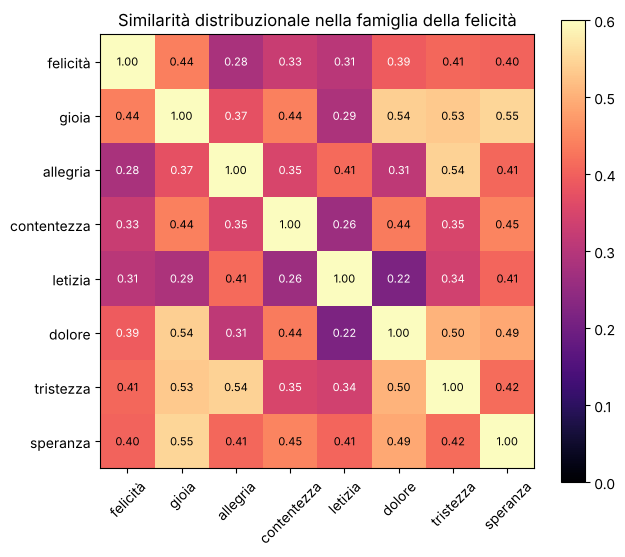

In [7]:
parole_felici = ["felicità", "gioia", "allegria", "contentezza", "letizia", "dolore", "tristezza", "speranza"]
S = pd.DataFrame([[similarita(a, b) for b in parole_felici] for a in parole_felici], index=parole_felici, columns=parole_felici)
plt.figure(figsize=(7, 6))
plt.imshow(S, cmap="magma", vmin=0, vmax=0.6)
plt.xticks(range(len(parole_felici)), parole_felici, rotation=45); plt.yticks(range(len(parole_felici)), parole_felici)
for i in range(len(parole_felici)):
    for j in range(len(parole_felici)):
        plt.text(j, i, f"{S.iloc[i, j]:.2f}", ha="center", va="center", color="white" if S.iloc[i, j] < 0.4 else "black", fontsize=8)
plt.title("Similarità distribuzionale nella famiglia della felicità"); plt.colorbar(); plt.show()

E la *beatitudine*?

In [8]:
print(vicini("beatitudine"))
print("Ma 'beato' c'è:", vicini("beato", 6))

'beatitudine' non è nel vocabolario (troppo rara o assente)
Ma 'beato' c'è: [('amor', 0.6), ('dolor', 0.6), ('pensier', 0.59), ('senno', 0.58), ('cor', 0.58), ('spirto', 0.57)]


Il modello conosce **solo il suo corpus**: una parola che non compare (o compare troppo poco) non ha un vettore.
Per lui *beatitudine* non esiste. I modelli grandi hanno vocabolari enormi, ma il principio non cambia: sanno ciò che hanno letto.

## 4. Dalle parole ai testi
Un modo semplice di rappresentare una frase: la **media** dei vettori delle sue parole. Ora possiamo confrontare frasi
che non condividono parole, cosa impossibile con il *bag of words* della lezione scorsa.

In [9]:
def vettore_testo(testo):
    vs = [VETTORI[INDICE[p]] for p in parole(testo) if p in INDICE]
    v = np.mean(vs, axis=0)
    return v / np.linalg.norm(v)

def sim_testi(a, b):
    return float(vettore_testo(a) @ vettore_testo(b))

coppie = [("provava una grande gioia", "sentiva una profonda letizia"),      # sinonimi: ora sono vicini
          ("provava una grande gioia", "provava un grande dolore"),          # contrari: vicinissimi!
          ("il burattino mangiò la pera", "sentiva una profonda letizia")]
for a, b in coppie:
    print(f"{sim_testi(a, b):.2f}   {a!r} ↔ {b!r}")

0.84   'provava una grande gioia' ↔ 'sentiva una profonda letizia'
0.89   'provava una grande gioia' ↔ 'provava un grande dolore'
0.63   'il burattino mangiò la pera' ↔ 'sentiva una profonda letizia'


Due osservazioni. I **contrari** (*gioia/dolore*) risultano più simili dei **sinonimi**: condividono le stesse costruzioni.
E con le medie anche frasi senza nulla in comune hanno similarità piuttosto alte: conta il **confronto relativo**, non il numero assoluto.

## 5. Ironia: il "sentimento del contrario"
Nel saggio *L'umorismo* (1908) Pirandello distingue il **comico** dall'**umorismo** con un esempio celebre. Leggiamolo dal corpus.

In [10]:
umorismo = leggi_testo(DATI / "testi" / "pirandello_umorismo.txt")
inizio = umorismo.index("Vedo una vecchia signora")
print(" ".join(umorismo[inizio:inizio + 1500].split()))

Vedo una vecchia signora, coi capelli ritinti, tutti unti non si sa di quale orribile manteca, e poi tutta goffamente imbellettata, e parata d'abiti giovanili. Mi metto a ridere. _Avverto_ che quella vecchia signora è _il contrario_ di ciò che una vecchia rispettabile signora dovrebbe essere. Posso così, a prima, giunta e superficialmente, arrestarmi a questa impressione comica. Il comico è appunto un _avvertimento del contrario_. Ma se ora interviene in me la riflessione, e mi suggerisce che quella vecchia signora non prova forse nessun piacere a pararsi così come un pappagallo, ma che forse ne soffre e lo fa soltanto perchè pietosamente s'inganna che, parata così, nascondendo così le rughe e le canizie, riesca a trattenere a sè l'amore del marito molto più giovine di lei, ecco che io non posso più riderne come prima, perchè appunto la riflessione, lavorando in me, mi ha fatto andar oltre a quel primo avvertimento, o piuttosto, più addentro: da quel primo avvertimento _del contrario_ 

L'umorismo nasce dalla **riflessione** su una situazione: le parole sono le stesse, il senso cambia. Un vettore costruito con le
parole non può vedere questa differenza. Proviamo con una frase ironica e la stessa frase detta sul serio:

In [11]:
sul_serio = "Che bella giornata, sono proprio felice."
ironica   = "Che bella giornata, sono proprio felice."   # detta sotto il diluvio, dopo aver perso il treno
print("Similarità:", round(sim_testi(sul_serio, ironica), 2))
print("Il vettore è identico perché le parole sono identiche: il contesto della situazione non è nel testo.")

Similarità: 1.0
Il vettore è identico perché le parole sono identiche: il contesto della situazione non è nel testo.


## 6. Creatività: le parole nuove
I poeti inventano parole e accostamenti. Un modello distribuzionale non ha vettori per le parole che non ha visto, e tende a
considerare "strano" (cioè poco probabile) ciò che è nuovo.

In [12]:
for p in ["felicità", "felicitudine", "contentezza", "incontentabile", "gioiosità", "mattinata"]:
    print(f"{p:>15}:", "✔ nel vocabolario" if p in INDICE else "✘ sconosciuta")

       felicità: ✔ nel vocabolario
   felicitudine: ✘ sconosciuta
    contentezza: ✔ nel vocabolario
 incontentabile: ✘ sconosciuta
      gioiosità: ✘ sconosciuta
      mattinata: ✘ sconosciuta


## 7. Bias: che cosa eredita un modello dal suo corpus
Gli embeddings riflettono le **associazioni del corpus**: chi scrive, quando, su chi. Il nostro corpus è fatto di libri
dell'Ottocento e del primo Novecento, scritti quasi tutti da uomini. Guardiamo i vicini di *donna* e di *uomo*.

In [13]:
pd.DataFrame({"donna": [w for w, s in vicini("donna", 12)], "uomo": [w for w, s in vicini("uomo", 12)]})

,donna,uomo
0,mimma,quel
1,lei,quell
2,povera,quello
3,buona,anche
4,bella,altro
5,mia,lui
6,sola,certo
7,ella,questo
8,quella,era
9,allora,stato


*Donna* sta con aggettivi **valutativi** (*povera, buona, bella, sola*); *uomo* con parole grammaticali. Nel corpus la donna
è soprattutto **descritta e giudicata**. Non è un fatto sul mondo, è un fatto sui **testi** che il modello ha letto.

Un altro strumento: un **asse semantico**. Costruiamo la direzione che va da *infelice* a *felice* (usando più parole per polo,
per ridurre il rumore) e misuriamo dove cadono altre parole.

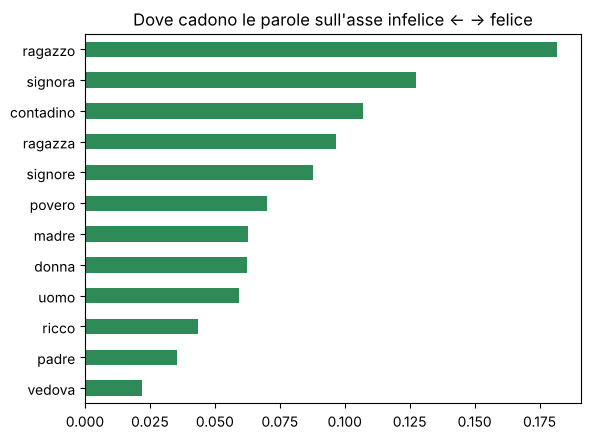

In [14]:
def asse(positivi, negativi):
    v = np.mean([VETTORI[INDICE[p]] for p in positivi], axis=0) - np.mean([VETTORI[INDICE[p]] for p in negativi], axis=0)
    return v / np.linalg.norm(v)

felice_infelice = asse(["felice", "lieto", "contento", "gioia", "allegria"], ["infelice", "triste", "misero", "dolore", "tristezza"])
gruppo = ["donna", "uomo", "madre", "padre", "ragazza", "ragazzo", "vedova", "contadino", "signora", "signore", "povero", "ricco"]
proiezioni = pd.Series({p: float(VETTORI[INDICE[p]] @ felice_infelice) for p in gruppo}).sort_values()
proiezioni.plot(kind="barh", color=["firebrick" if v < 0 else "seagreen" for v in proiezioni])
plt.title("Dove cadono le parole sull'asse infelice ← → felice"); plt.show()

Tutte le parole cadono dal lato "felice" (i vettori condividono una componente comune), quindi conta solo la **posizione relativa**:
*ragazzo* (il mondo di Pinocchio) è in cima, *vedova* in fondo. Interpretate con **molta cautela**: con un corpus piccolo le differenze sono rumorose, e basta cambiare una parola nei poli
per spostarle. Ma lo stesso metodo, applicato a embeddings addestrati su miliardi di parole del web, ha mostrato
associazioni stereotipate (professioni, genere, provenienza) molto stabili. Quando questi modelli vengono usati per
selezionare curriculum o moderare contenuti, i bias del corpus diventano **decisioni** che riguardano persone vere.

## 8. E i modelli "veri"?
I nostri vettori sono fatti a mano con 600.000 parole. Modelli come *word2vec* o *fastText* (anni 2010) imparano vettori
simili da miliardi di parole con una piccola rete neurale. I modelli linguistici attuali calcolano **un vettore diverso per
ogni occorrenza** di una parola, in base alla frase in cui compare (*embeddings contestuali*): così *felice* in una frase
ironica può avere un vettore diverso da *felice* in una frase sincera. Il principio però resta quello di Firth: **il significato
come uso nei contesti**. Con i suoi pregi e i suoi limiti.

## Riepilogo
- **Ipotesi distribuzionale**: parole in contesti simili hanno significati simili.
- **Embedding**: una lista di numeri per parola, appresa dalle co-occorrenze (qui: PPMI + SVD).
- Vicini e similarità rivelano **registri** e **costruzioni**, ma mettono insieme anche i **contrari**.
- Gli embeddings non vedono l'**ironia** (che sta nella situazione) né le **parole nuove**, ed ereditano i **bias** del corpus.

## Esercizi
Soluzioni in `solutions/07_semantica_distribuzionale_soluzioni.ipynb`.

**Esercizio 1 — I vostri vicini.** Scegliete tre parole che vi interessano (un luogo, un sentimento, un oggetto) e guardatene i vicini.
I risultati riflettono il significato della parola, l'opera in cui compare di più, o una costruzione grammaticale?

**Esercizio 2 — Un altro asse.** Costruite un asse **povero ← → ricco** (o **campagna ← → città**) con almeno tre parole per polo
e proiettate una lista di parole (persone, luoghi, sentimenti). Che cosa vi sembra che il corpus "pensi"? Quanto è stabile il
risultato se cambiate le parole dei poli?

**Esercizio 3 — La finestra.** Ricostruite i vettori con `finestra=2` e con `finestra=10` e confrontate i vicini di *gioia* e di *felicità*.
Le finestre strette tendono a catturare somiglianze **grammaticali** (parole che si usano allo stesso modo), quelle larghe
somiglianze **tematiche** (parole dello stesso argomento). Lo vedete?

In [15]:
# Esercizio 1

In [16]:
# Esercizio 2

In [17]:
# Esercizio 3